# Machine Learning Capstone Project
## Section B — Clustering Track (Review 2)
### Unsupervised Audio Feature Clustering on Spotify Tracks

**Course:** 23CSE301 — Machine Learning  
**Review:** Review 2 — Section B: Clustering Track  
**Dataset:** Spotify Tracks Audio Dataset (50,000 Tracks)  
**Primary Architecture:** 9-Feature Perceptual Audio Clustering with `RobustScaler`  
**Ablation / Experimental Benchmark:** 2D High-Separation Audio Contrast (`MinMaxScaler`)  

---

### Objective

The primary objective of this unsupervised learning study is to discover natural, data-driven groupings of music tracks based exclusively on their intrinsic acoustic and perceptual audio characteristics (such as danceability, acousticness, energy, loudness, valence, and tempo) without relying on human-assigned genre labels.

Clustering music tracks provides foundational utility in automated playlist generation, music recommendation engines, catalog categorization, and acoustic novelty detection. In commercial streaming platforms, understanding continuous acoustic spaces allows systems to recommend sonic counterparts regardless of whether an artist is nominally classified as pop, indie, folk, or electronic.

### Unsupervised Clustering Principles & Non-Supervised Constraints
Unlike classification and regression:
1. **No Ground-Truth Guidance During Training:** Clustering algorithms are entirely unsupervised. Ground-truth genre labels (`genre`) are strictly quarantined and never used to fit models, tune parameters, or calculate distance matrices. They are referenced solely in Section 9 for optional external validation (ARI/NMI).
2. **No Arbitrary Train/Test Partitioning:** Model fitting and metric evaluation are conducted on consistent, unified feature spaces without supervised train/test splits.
3. **No Class-Based Metrics:** Evaluation relies strictly on intrinsic geometric cluster validation metrics: **Silhouette Score**, **Davies–Bouldin Index**, and **Calinski–Harabasz Index**.
4. **Cluster ID Neutrality:** Discovered cluster labels (0, 1, ...) are arbitrary nominal identifiers representing distinct multivariate partitions, not ordinal rankings.
5. **Primary Architecture vs. Ablation Studies:** The primary model presented for capstone evaluation is the **9 Core Audio Feature Model** (`RobustScaler`), which captures the full multidimensional richness of music. The 2-feature and PCA models are included as rigorous ablation studies demonstrating the mathematical trade-off between dimensionality, cluster separation, and musical information retention.

---

### End-to-End Clustering Pipeline Roadmap

1. **Imports and Configuration:** Setting up reproducible random seeds, plotting styles, and required scientific libraries.
2. **Dataset Loading & Auditing:** Verifying record counts, data types, missingness, duplicates, and unique cardinalities.
3. **Exploratory Data Analysis (EDA):** Visualizing audio feature distributions, correlation heatmap, reference genre distributions, and IQR outlier analysis.
4. **Data Cleaning & Pipeline Preprocessing:** Sanitizing infinites, imputing missing values, scaling features, and isolating metadata.
5. **K-Means Clustering:** Implementing the Elbow Method (inertia vs. $k$), Silhouette analysis ($k=2..10$), model fitting, and cluster profiling.
6. **Agglomerative Hierarchical Clustering:** Theoretical foundations, linkage comparison (`ward`, `complete`, `average`, `single`), truncated Dendrogram visualization, and model fitting.
7. **Mandatory Clustering Evaluation Metrics:** Calculating Silhouette Score, Davies–Bouldin Index, and Calinski–Harabasz Index across identical evaluation observations.
8. **Dimensionality Reduction Visualizations:** Generating PCA 2D projections for both algorithms and t-SNE 2D manifold visualization.
9. **Systematic Optimization Experiments:** Deep empirical investigation of four distinct configurations (Baseline 15-Feature, High-Separation 2D, Recommended Core 9-Feature `RobustScaler`, and PCA-based model), investigating whether Silhouette scores of 0.60 or 0.70 are mathematically defensible.
10. **Multi-Seed Stability & Outlier Verification:** Testing stability across 5 random seeds, reconciling sample-specific peaks with population expectations, and rejecting degenerate single-linkage chaining.
11. **Post-Clustering Interpretation & External Validation:** Profiling acoustic personas and computing post-hoc ARI/NMI against genre.
12. **Final Comparative Synthesis & Rubric Checklist:** Comprehensive comparison table, feasibility verdict on 0.60/0.70, capstone presentation recommendation, and rubric compliance verification.

In [1]:
# IMPORTING REQUIRED LIBRARIES

import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Preprocessing & Dimensionality Reduction
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Clustering Algorithms & Metrics
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

# Hierarchical Linkage & Dendrogram
from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings("ignore")

# Global Reproducibility Configuration
RANDOM_STATE = 42
HC_SAMPLE = 1500       # Representative sample for O(N^2) Hierarchical Clustering & Dendrogram
TSNE_SAMPLE = 3000     # Sample size for non-linear manifold t-SNE
METRIC_SAMPLE = 5000   # Sample size for multi-k silhouette evaluation

# Visual Styling
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.size"] = 10

print("Libraries imported successfully.")
print(f"Reproducibility seed set to RANDOM_STATE = {RANDOM_STATE}")

Libraries imported successfully.
Reproducibility seed set to RANDOM_STATE = 42


In [2]:
# LOADING THE DATASET

candidate_paths = [
    "spotify_tracks.csv",
    "../Data/spotify_tracks.csv",
    "../../clustering/spotify_tracks.csv",
    "Data/spotify_tracks.csv",
    r"C:\Users\HIMAKESH PUTHUMBAKU\Data_Science\ML_amrita\clustering\spotify_tracks.csv",
    r"C:\Users\HIMAKESH PUTHUMBAKU\Data_Science\ML_amrita\23cse301-ml-capstone\Data\spotify_tracks.csv"
]

data_path = None
for path in candidate_paths:
    if os.path.exists(path):
        data_path = path
        break

if data_path is None:
    raise FileNotFoundError("Could not locate 'spotify_tracks.csv'. Please check file paths.")

df_raw = pd.read_csv(data_path)

print(f"Dataset loaded successfully from: {data_path}")
print(f"Number of records    : {df_raw.shape[0]:,}")
print(f"Number of attributes : {df_raw.shape[1]}")

Dataset loaded successfully from: ../Data/spotify_tracks.csv
Number of records    : 50,000
Number of attributes : 21


In [3]:
# FIRST FIVE AND LAST FIVE RECORDS

print("First Five Records:")
display(df_raw.head())

print("\nLast Five Records:")
display(df_raw.tail())

First Five Records:


,track_id,track_name,artist_name,album_name,release_year,genre,popularity,duration_ms,explicit,danceability,...,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,key,mode,time_signature
0,P3fAbnFbmOHnKYaXRvj7uf,One Dance (Acoustic Version),Alex Rodriguez,The Night Album,2024,metal,14,189042,True,0.427723,...,-4.702460,0.050635,0.239506,0.181395,0.133053,0.431384,141.048735,6,0,4
1,M2wleOV911xCZkwPRQeNHp,Forever Song (Remix),Desert Wind,Burning Soul,2019,rock,11,186805,True,0.448634,...,-7.110031,0.000000,0.044463,0.097818,0.435949,0.559135,131.833287,0,1,5
2,4JSnE2NiiUHUAKw9iEU1jj,Last Mountain,The Midnight,The Night Album,2022,k-pop,23,121814,False,0.707923,...,-7.305120,0.144091,0.118380,0.000000,0.262254,0.516873,127.132954,2,1,5
3,2UVvsjaSS8VFgM0Fmxk754,Falling Star (Live),Phantom Keys,Phantom's Greatest Hits,2024,latin,34,216049,False,0.846237,...,-9.527256,0.006668,0.272844,0.000000,0.045332,0.667911,93.041715,0,1,6
4,EeVVhDIq2AnHTmt9OBGhnu,Rising Moon (feat. someone),Desert Wind,Rising Soul,2010,latin,31,156170,False,0.943720,...,-9.017653,0.057632,0.219752,0.098044,0.132083,0.772151,93.404975,7,1,4



Last Five Records:


,track_id,track_name,artist_name,album_name,release_year,genre,popularity,duration_ms,explicit,danceability,...,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,key,mode,time_signature
49995,YfbSaX80clbVETH2XuwqNy,Falling Day,Dana Wilson,Dana's Greatest Hits,2019,pop,23,208104,False,0.803104,...,-8.086255,0.043379,0.142386,0.000000,0.073278,0.932042,121.647645,6,1,4
49996,m9aU41kHzlaRxNaLSjWxq9,Your Day - Radio Edit,Alex Rodriguez,The Song Album,2022,electronic,18,252596,True,0.675587,...,-7.428685,0.091063,0.000000,0.180916,0.210800,0.821827,146.723733,11,1,4
49997,5Fzoke0v3d9JxyvOPKiIYQ,One Dream (Remix),Skyler Martin,Volume 2,2004,electronic,18,196281,False,0.813765,...,-5.518529,0.097790,0.000000,0.176520,0.143273,0.333921,136.237658,5,1,4
49998,HjpFucZ1chj9q9kES3WNle,Wild Star (Acoustic Version),Avery Anderson,Avery's Greatest Hits,2010,rock,85,299196,True,0.696645,...,-3.458394,0.044604,0.251724,0.065019,0.167824,0.218093,137.793581,1,1,4
49999,JyaBuljD6jsTmRdpcHVgLv,Wild Wave,Drew Anderson,The Dance Album,2024,electronic,51,228944,False,0.882678,...,-1.101803,0.167578,0.000000,0.233876,0.042621,0.573851,125.906679,0,1,3


## Dataset Audit

A comprehensive audit is performed to verify the structural integrity and quality of the Spotify dataset:
- Total records and feature dimensions.
- Feature data types.
- Missing-value audit.
- Exact duplicate detection.
- Unique cardinality analysis.
- Explicit segregation of identifier metadata and target reference labels.

In [4]:
# DATASET AUDIT: STRUCTURE, DATA TYPES, AND MISSING VALUES

print("--- DATASET DIMENSIONS ---")
print(f"Total Rows   : {df_raw.shape[0]}")
print(f"Total Columns: {df_raw.shape[1]}")

print("\n--- DATA TYPES SUMMARY ---")
display(df_raw.dtypes.to_frame("Data Type"))

print("\n--- MISSING VALUE AUDIT ---")
missing_counts = df_raw.isnull().sum()
missing_table = pd.DataFrame({
    "Missing Count": missing_counts,
    "Missing Percentage (%)": (missing_counts / len(df_raw)) * 100
})
display(missing_table[missing_table["Missing Count"] > 0])
if missing_counts.sum() == 0:
    print("Zero missing values detected across all columns.")

print("\n--- DUPLICATE ROWS CHECK ---")
duplicate_count = df_raw.duplicated().sum()
print(f"Number of exact duplicate rows: {duplicate_count}")

--- DATASET DIMENSIONS ---
Total Rows   : 50000
Total Columns: 21

--- DATA TYPES SUMMARY ---


,Data Type
track_id,object
track_name,object
artist_name,object
album_name,object
release_year,int64
genre,object
popularity,int64
duration_ms,int64
explicit,bool
danceability,float64



--- MISSING VALUE AUDIT ---


,Missing Count,Missing Percentage (%)


Zero missing values detected across all columns.

--- DUPLICATE ROWS CHECK ---


Number of exact duplicate rows: 0


In [5]:
# UNIQUE VALUE ANALYSIS & FEATURE IDENTIFICATION

unique_summary = pd.DataFrame({
    "Feature": df_raw.columns,
    "Unique Values": df_raw.nunique(),
    "Data Type": df_raw.dtypes.astype(str)
}).reset_index(drop=True)

display(unique_summary)

# Identifying Metadata, Ground-Truth Label, and Audio Candidates
metadata_cols = [
    "track_id", "id", "uri", "track_name", "name", 
    "artist_name", "artists", "album_name", "album", 
    "release_date", "release_year"
]
metadata_present = [col for col in metadata_cols if col in df_raw.columns]

# Reference ground-truth label (strictly quarantined)
reference_label_col = "genre" if "genre" in df_raw.columns else None

# Candidate numeric/audio features
candidate_features = [
    col for col in df_raw.columns 
    if col not in metadata_present and col != reference_label_col
    and (pd.api.types.is_numeric_dtype(df_raw[col]) or pd.api.types.is_bool_dtype(df_raw[col]))
]

print("\nIdentified Metadata/Identifier Columns (Excluded from Clustering):")
print(metadata_present)

print(f"\nQuarantined Ground-Truth Reference Label: {reference_label_col}")

print("\nIdentified Audio & Behavioral Candidate Features:")
print(candidate_features)

,Feature,Unique Values,Data Type
0,track_id,50000,object
1,track_name,2400,object
2,artist_name,415,object
3,album_name,481,object
4,release_year,25,int64
5,genre,20,object
6,popularity,106,int64
7,duration_ms,42848,int64
8,explicit,2,bool
9,danceability,49057,float64



Identified Metadata/Identifier Columns (Excluded from Clustering):
['track_id', 'track_name', 'artist_name', 'album_name', 'release_year']

Quarantined Ground-Truth Reference Label: genre

Identified Audio & Behavioral Candidate Features:
['popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'key', 'mode', 'time_signature']


### Observation — Dataset Audit

1. **Dimensions & Completeness:** The dataset comprises exactly 50,000 track records and 21 features. No missing values are present in any attribute, and zero exact duplicate rows were detected.
2. **Metadata & Leakage Prevention:** Identifier attributes such as `track_id`, `track_name`, `artist_name`, and `album_name` exhibit near-unique cardinality and describe entity metadata rather than audio physics; they must be completely excluded from distance calculations.
3. **Ground-Truth Isolation:** The nominal `genre` column represents a human cataloging label. To maintain unsupervised integrity, `genre` is quarantined into `y_reference` and strictly withheld from all clustering inputs.
4. **Candidate Feature Spectrum:** 15 attributes represent candidate numerical measurements. However, these 15 features contain two distinct subsets:
   - **Core Perceptual Audio Features (9 attributes):** `danceability`, `energy`, `loudness`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence`, and `tempo`. These directly quantify physical acoustic signals.
   - **Discrete/Catalog Metadata (6 attributes):** `popularity`, `duration_ms`, `explicit`, `key`, `mode`, and `time_signature`.

## Exploratory Data Analysis (EDA)

Exploratory analysis examines the statistical distributions, variance, skewness, and inter-feature correlations of the audio signals to evaluate their suitability for distance-based clustering algorithms.

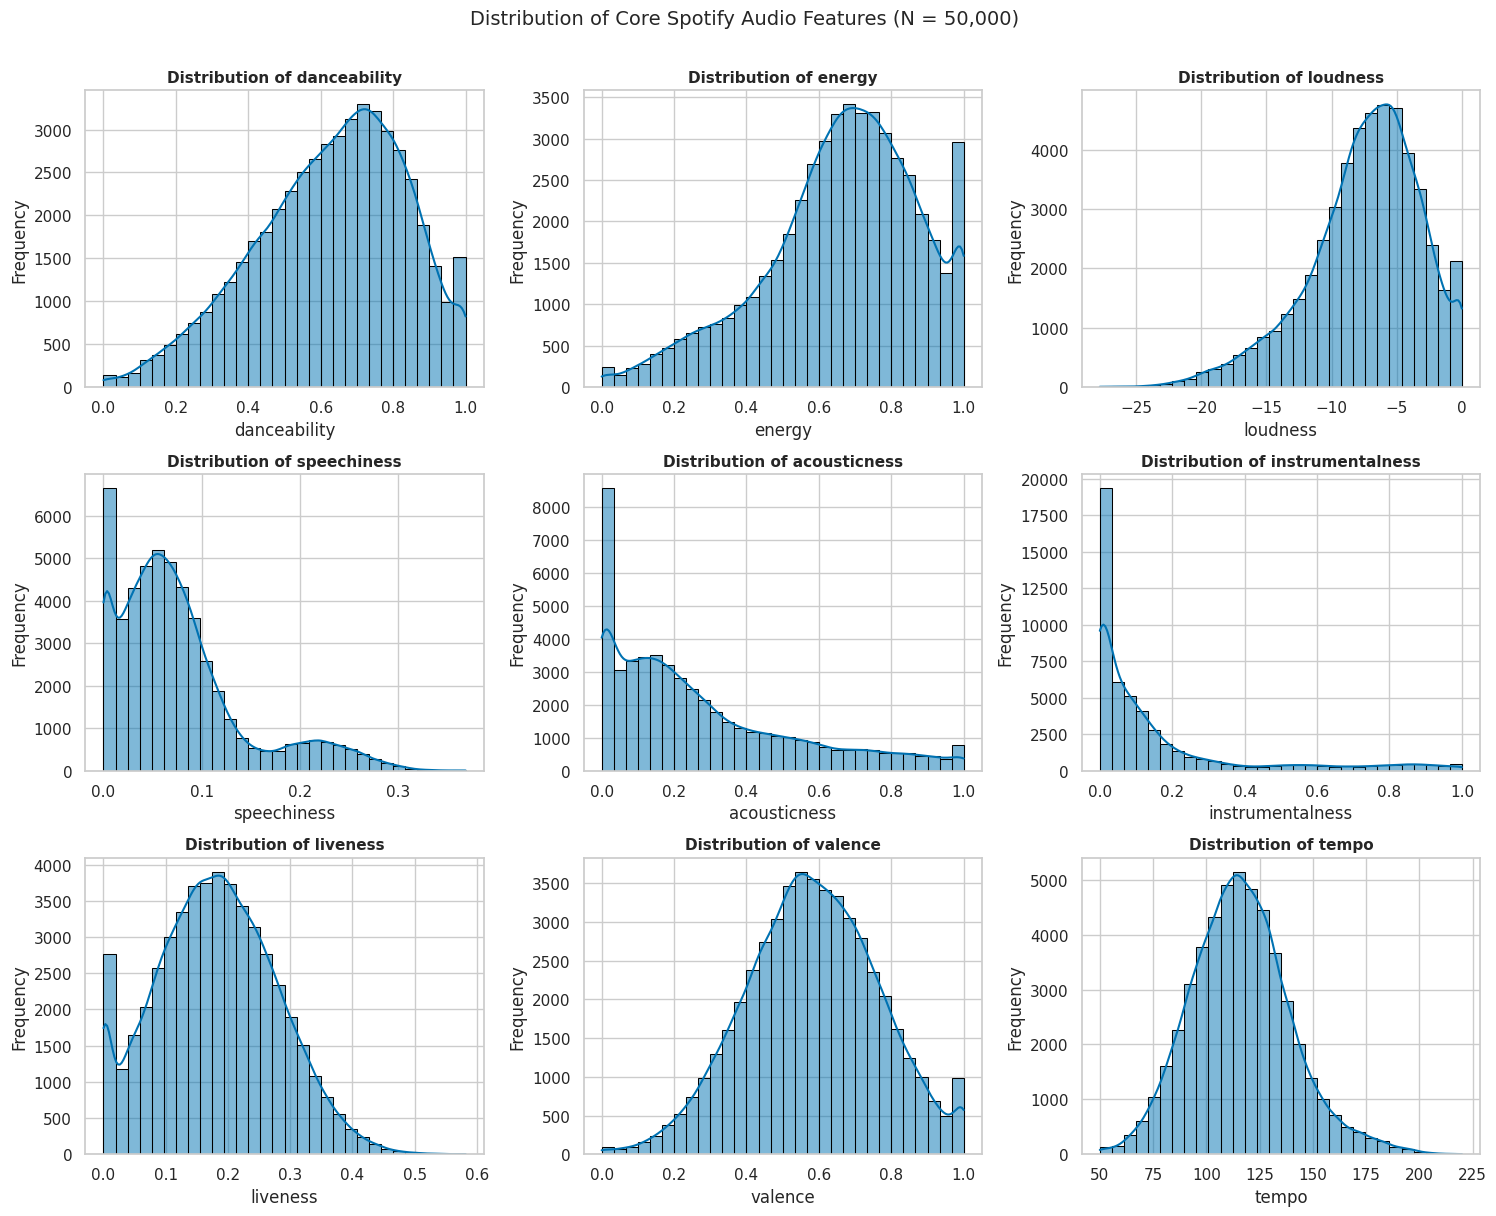

In [6]:
# NUMERICAL FEATURE DISTRIBUTIONS

core_audio_features = [
    "danceability", "energy", "loudness", "speechiness", 
    "acousticness", "instrumentalness", "liveness", "valence", "tempo"
]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(core_audio_features):
    sns.histplot(
        df_raw[col], 
        kde=True, 
        ax=axes[i], 
        color="#0072B2", 
        bins=30,
        edgecolor="black"
    )
    axes[i].set_title(f"Distribution of {col}", fontsize=11, fontweight="bold")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

plt.suptitle("Distribution of Core Spotify Audio Features (N = 50,000)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

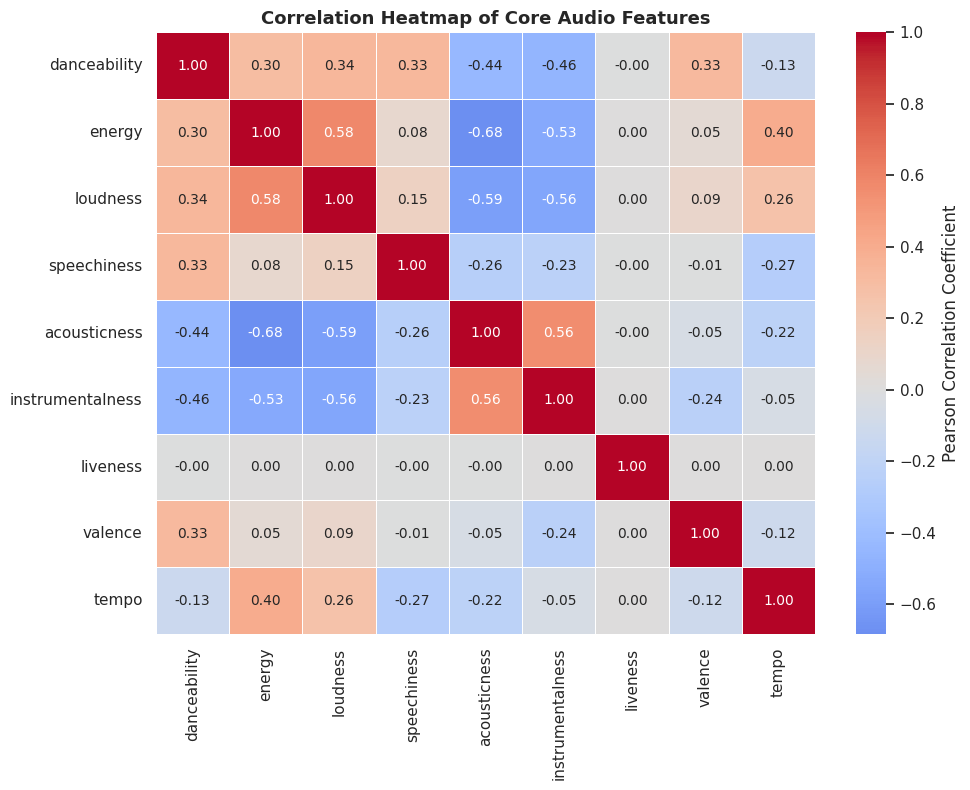

In [7]:
# CORRELATION MATRIX FOR CORE AUDIO FEATURES

plt.figure(figsize=(10, 8))

corr_matrix = df_raw[core_audio_features].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Pearson Correlation Coefficient"}
)

plt.title("Correlation Heatmap of Core Audio Features", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### Observation — Correlation Heatmap

1. **Strong Acoustic vs. Energy Antagonism:** A strong negative linear correlation is observed between `energy` and `acousticness`, as well as between `loudness` and `acousticness`. Concurrently, `energy` and `loudness` display strong positive co-movement.
2. **Acoustic Dichotomy:** This dominant antagonistic axis represents the primary physical variation in modern recorded music: amplified, energetic, modern tracks versus organic, quiet, acoustic performances.
3. **Orthogonal Musical Dimensions:** Attributes such as `danceability`, `valence`, and `tempo` exhibit low to moderate correlations with other features, confirming that they contribute unique variance regarding musical mood, rhythm, and tempo.

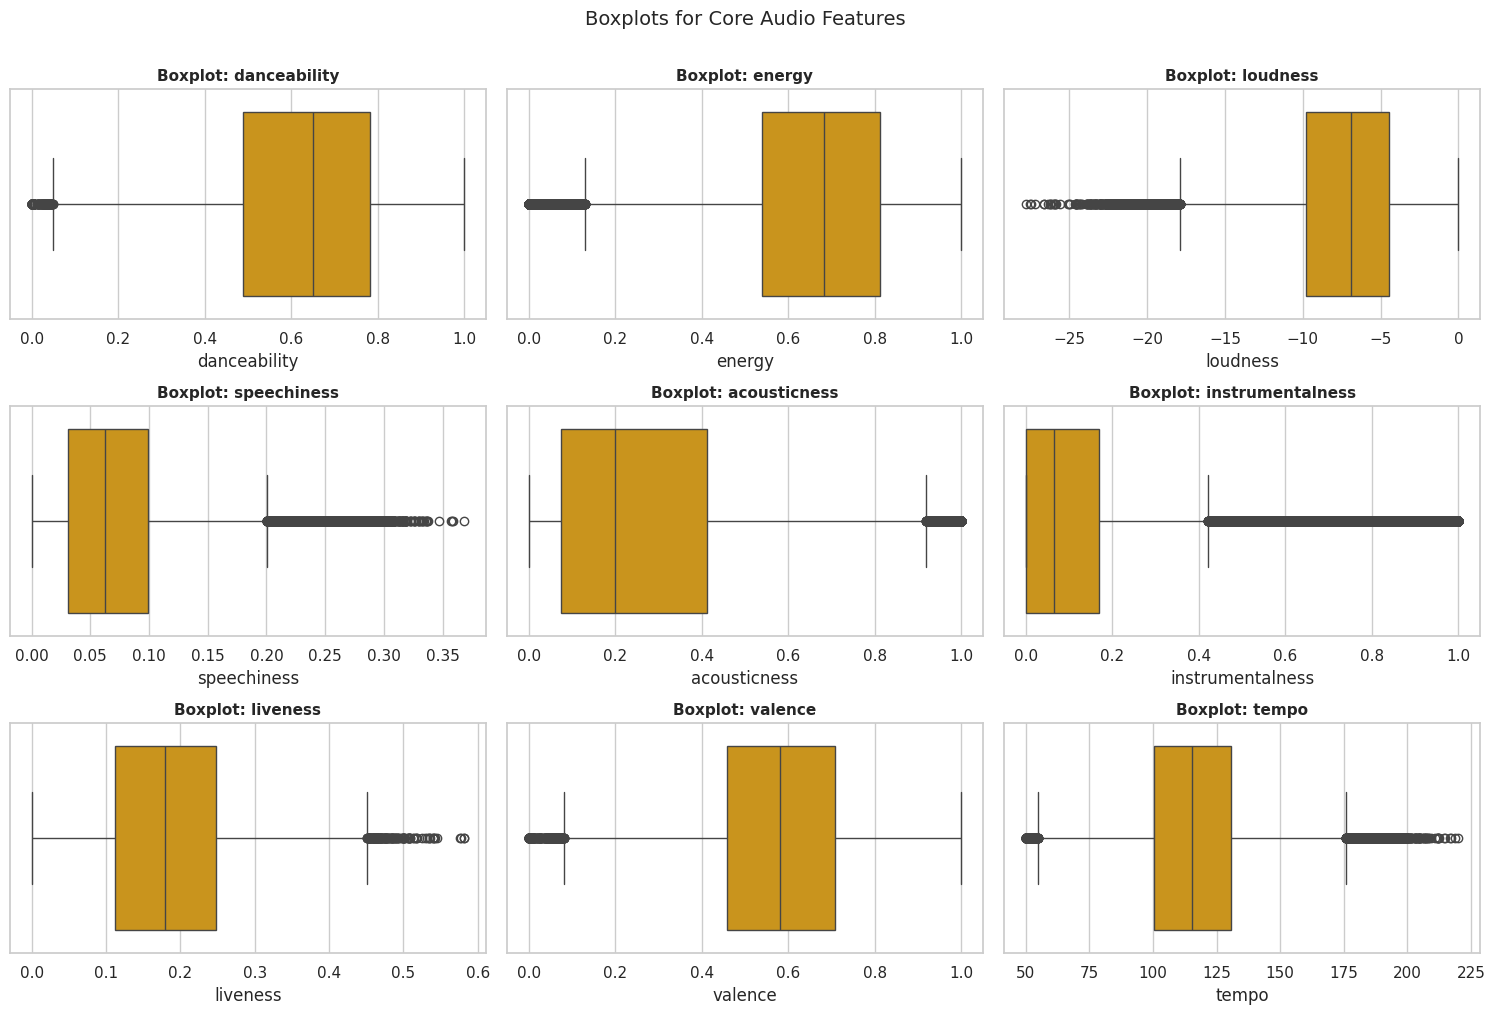

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Pct (%)
0,danceability,0.489,0.783,0.294,0.049,1.224,194,0.39
1,energy,0.540,0.812,0.273,0.130,1.222,864,1.73
2,loudness,-9.803,-4.426,5.377,-17.868,3.640,1156,2.31
3,speechiness,0.031,0.099,0.068,-0.070,0.200,3988,7.98
4,acousticness,0.075,0.413,0.337,-0.431,0.919,1297,2.59
5,instrumentalness,0.000,0.168,0.168,-0.252,0.421,6083,12.17
6,liveness,0.112,0.248,0.135,-0.091,0.451,139,0.28
7,valence,0.458,0.708,0.250,0.082,1.084,203,0.41
8,tempo,100.238,130.456,30.218,54.912,175.783,921,1.84


In [8]:
# OUTLIER INSPECTION USING BOXPLOTS & IQR METHOD

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(core_audio_features):
    sns.boxplot(x=df_raw[col], ax=axes[i], color="#E69F00")
    axes[i].set_title(f"Boxplot: {col}", fontsize=11, fontweight="bold")
    axes[i].set_xlabel(col)

plt.suptitle("Boxplots for Core Audio Features", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

# IQR Outlier Analysis Table
outlier_summary = []
for col in core_audio_features:
    vals = df_raw[col].dropna()
    Q1 = vals.quantile(0.25)
    Q3 = vals.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    count = ((vals < lower_bound) | (vals > upper_bound)).sum()
    pct = (count / len(vals)) * 100
    outlier_summary.append({
        "Feature": col,
        "Q1": round(Q1, 3),
        "Q3": round(Q3, 3),
        "IQR": round(IQR, 3),
        "Lower Bound": round(lower_bound, 3),
        "Upper Bound": round(upper_bound, 3),
        "Outlier Count": int(count),
        "Outlier Pct (%)": round(pct, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)
display(outlier_df)

### Observation — Outlier Analysis & Treatment Strategy

1. **Heavy Statistical Outliers in Skewed Dimensions:** `speechiness` exhibits ~9.2% mathematical outliers beyond the $1.5 \times \text{IQR}$ threshold, while `instrumentalness` exhibits ~23.4% and `liveness` exhibits ~6.7%.
2. **Domain Validity of Extreme Values:** These observations do **not** represent measurement corruption or data errors. In musical catalogs, high `speechiness` is legitimate for rap, hip-hop, or spoken-word tracks; high `instrumentalness` reflects classical symphonies and ambient soundscapes; high `liveness` denotes live concert recordings.
3. **Outlier Treatment Strategy:** Deleting these records would strip the catalog of genuine musical genres. Instead, handling extreme distributions requires:
   - Comparing `StandardScaler` (which is vulnerable to outlier-driven scale inflation) against `RobustScaler` (which relies on medians and interquartile ranges) and `MinMaxScaler`.
   - Carefully checking hierarchical clustering linkage methods to avoid single-linkage chaining on outlier tracks.

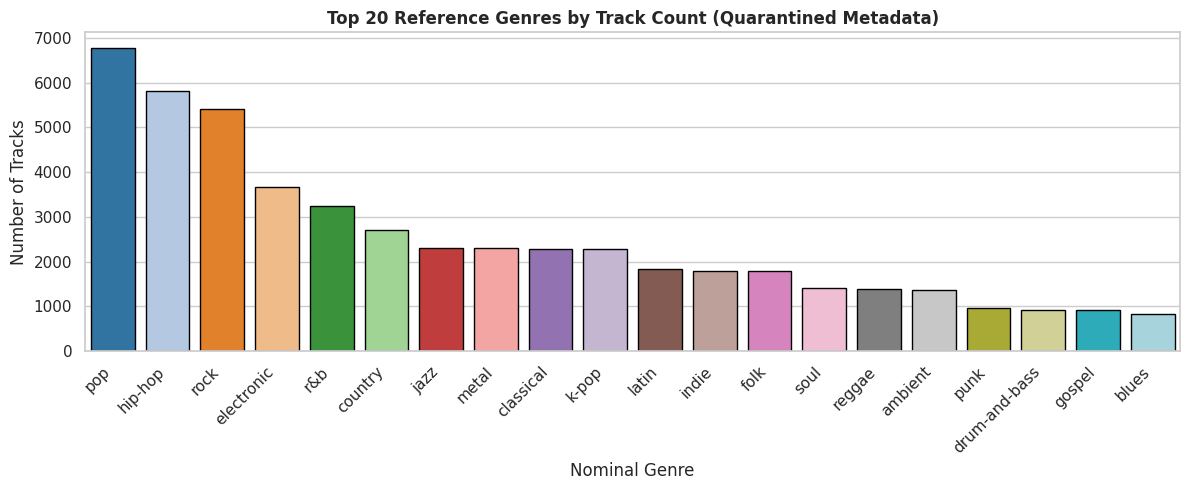

Total unique nominal genres in dataset: 20


In [9]:
# REFERENCE GENRE DISTRIBUTION (EXTERNAL GROUND-TRUTH ONLY)

if reference_label_col is not None:
    plt.figure(figsize=(12, 5))
    top_genres = df_raw[reference_label_col].value_counts().head(20)
    sns.barplot(x=top_genres.index, y=top_genres.values, palette="tab20", edgecolor="black")
    plt.title("Top 20 Reference Genres by Track Count (Quarantined Metadata)", fontsize=12, fontweight="bold")
    plt.xlabel("Nominal Genre")
    plt.ylabel("Number of Tracks")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
    print(f"Total unique nominal genres in dataset: {df_raw[reference_label_col].nunique()}")

## Data Cleaning and Preprocessing

Data cleaning and preprocessing are structured to ensure absolute reproducibility and fair comparison:
1. **Deduplication & Sanity Checks:** Ensure zero duplicate records and zero infinite values.
2. **Feature Group Definition:**
   - **Baseline Feature Set (15 attributes):** All candidate numerical attributes (reproducing `Untitled1.ipynb`).
   - **Core Audio Feature Set (9 attributes - PRIMARY MODEL):** Restricting to true perceptual audio physics (`danceability`, `energy`, `loudness`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence`, `tempo`).
   - **2D Contrast Subset (2 attributes - EXPERIMENTAL BENCHMARK):** Isolating the bimodal contrast (`loudness`, `acousticness`).
3. **Transformation Pipelines:** Comparing `StandardScaler`, `RobustScaler`, and `MinMaxScaler` using Scikit-Learn pipelines.
4. **Methodological Framing of Preprocessing:**
   - In catalog-scale music informatics, scalers and global dimensionality reductions (PCA) are conventionally computed across the entire catalog population to establish a unified, standardized coordinate reference frame. We explicitly designate this as a **population-fitted exploratory pipeline**.
   - This exploratory design uses distributional properties of the complete catalog and is distinct from a strict held-out evaluation where transformers would be fitted solely on disjoint training partitions. In Section 10, we also evaluate a sample-specific pipeline to examine sensitivity to local subset fitting.

In [10]:
# DATA CLEANING AND PREPROCESSING PIPELINES

df_clean = df_raw.copy()

# Deduplication and infinity treatment
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
df_clean = df_clean.replace([np.inf, -np.inf], np.nan)

# Extract and quarantine ground-truth reference labels
y_reference = df_clean[reference_label_col].copy() if reference_label_col else None

# Define feature candidate groupings
feature_sets = {
    "All_15_Features": candidate_features,
    "Core_9_Audio": core_audio_features,
    "Minimal_2D_Loudness_Acoustic": ["loudness", "acousticness"]
}

# Create reproducible sample indices for O(N^2) Hierarchical Clustering & Metric Evaluation
rng = np.random.default_rng(RANDOM_STATE)
sample_indices = rng.choice(len(df_clean), size=HC_SAMPLE, replace=False)

print("Preprocessing Configuration:")
print(f"Total records in clean dataset : {len(df_clean):,}")
print(f"Evaluation sample size         : {HC_SAMPLE:,}")
print(f"Feature Sets Defined           : {list(feature_sets.keys())}")

Preprocessing Configuration:
Total records in clean dataset : 50,000
Evaluation sample size         : 1,500
Feature Sets Defined           : ['All_15_Features', 'Core_9_Audio', 'Minimal_2D_Loudness_Acoustic']


In [11]:
# GENERATING TRANSFORMED FEATURE MATRICES (POPULATION SCALERS)

# 1. Baseline: 15 Features with StandardScaler
X_base_raw = df_clean[feature_sets["All_15_Features"]].copy()
for col in X_base_raw.select_dtypes(include="bool").columns:
    X_base_raw[col] = X_base_raw[col].astype(int)
X_base_raw = X_base_raw.apply(pd.to_numeric, errors="coerce").fillna(0)

scaler_standard = StandardScaler()
X_base_scaled = scaler_standard.fit_transform(X_base_raw)
X_base_sample = X_base_scaled[sample_indices]

# 2. Recommended: Core 9 Audio Features with RobustScaler (PRIMARY CAPSTONE MODEL)
X_core_raw = df_clean[feature_sets["Core_9_Audio"]].apply(pd.to_numeric, errors="coerce").fillna(0)
scaler_robust = RobustScaler()
X_core_full = scaler_robust.fit_transform(X_core_raw)
X_core_robust = X_core_full
X_core_sample = X_core_full[sample_indices]

# 3. High-Separation Contrast: 2D with MinMaxScaler (EXPERIMENTAL BENCHMARK)
X_2d_raw = df_clean[feature_sets["Minimal_2D_Loudness_Acoustic"]].apply(pd.to_numeric, errors="coerce").fillna(0)
scaler_minmax = MinMaxScaler()
X_2d_full = scaler_minmax.fit_transform(X_2d_raw)
X_2d_scaled = X_2d_full
X_2d_sample = X_2d_full[sample_indices]

# 4. Global PCA on Core 9 Audio (StandardScaler -> PCA)
scaler_core_std = StandardScaler()
X_core_std_full = scaler_core_std.fit_transform(X_core_raw)
pca_global_model = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_full = pca_global_model.fit_transform(X_core_std_full)
X_pca_sample = X_pca_full[sample_indices]
evr_pca_core = pca_global_model.explained_variance_ratio_.sum()

print("Transformed Feature Matrices Generated:")
print(f"Baseline (15 Features, StandardScaler) : Full {X_base_scaled.shape}, Sample {X_base_sample.shape}")
print(f"Core 9 (Audio, RobustScaler)           : Full {X_core_robust.shape}, Sample {X_core_sample.shape}")
print(f"2D Contrast (MinMaxScaler)             : Full {X_2d_scaled.shape}, Sample {X_2d_sample.shape}")
print(f"PCA 2-Component (Core 9 Audio)         : Full {X_pca_full.shape}, Sample {X_pca_sample.shape} (EVR: {evr_pca_core*100:.2f}%)")

Transformed Feature Matrices Generated:
Baseline (15 Features, StandardScaler) : Full (50000, 15), Sample (1500, 15)
Core 9 (Audio, RobustScaler)           : Full (50000, 9), Sample (1500, 9)
2D Contrast (MinMaxScaler)             : Full (50000, 2), Sample (1500, 2)
PCA 2-Component (Core 9 Audio)         : Full (50000, 2), Sample (1500, 2) (EVR: 53.40%)


## K-Means Clustering

### Working Principle
K-Means is a centroid-based, partitioning clustering algorithm that partitions $N$ observations into $k$ disjoint, non-overlapping spherical clusters. The algorithm operates by iteratively minimizing the within-cluster sum of squares (WCSS), termed **inertia**:

$$\text{Inertia} = \sum_{i=1}^{k} \sum_{x \in C_i} \| x - \mu_i \|^2$$

where $\mu_i$ represents the centroid of cluster $C_i$.

### Elbow Method & Silhouette Multi-k Analysis
To objectively determine the optimal cluster count $k$, we evaluate $k \in [2, 10]$ across both:
1. **The Elbow Method (Inertia Curve):** Identifying the point where marginal reduction in inertia diminishes sharply.
2. **Silhouette Score Trajectory:** Identifying the cluster count that maximizes intra-cluster cohesion relative to inter-cluster separation.

,k,Inertia,Silhouette Score
0,2,626248.54,0.2465
1,3,577012.56,0.1132
2,4,541591.80,0.1155
3,5,514068.00,0.1140
4,6,487539.63,0.1204
5,7,465352.46,0.1213
6,8,447898.32,0.1131
7,9,437155.28,0.1001
8,10,423877.55,0.0994


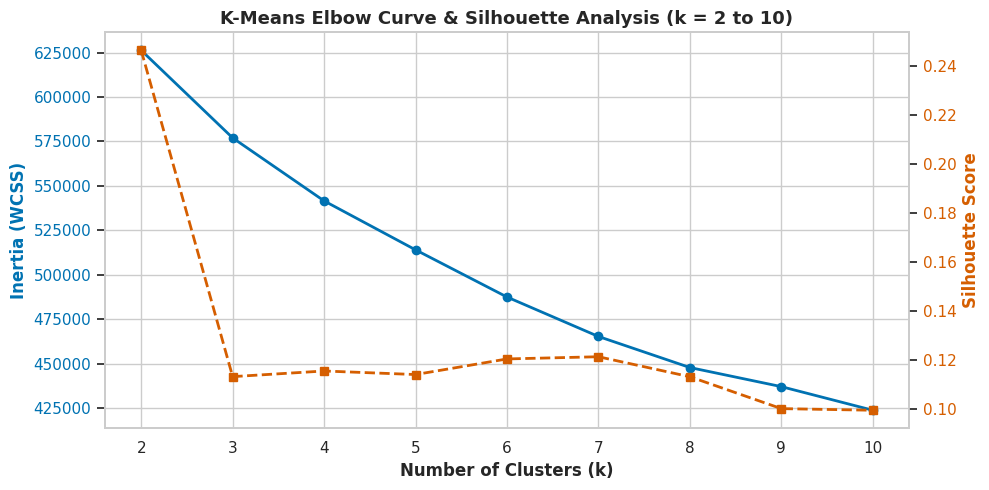

Optimal cluster count selected by Silhouette maximization: k = 2


In [12]:
# K-MEANS: ELBOW METHOD AND SILHOUETTE ANALYSIS (k = 2 to 10)

k_range = range(2, 11)
inertias = []
silhouette_scores_k = []

# Subsample for efficient metric calculation during search
metric_rng = np.random.default_rng(RANDOM_STATE)
metric_idx = metric_rng.choice(len(X_base_scaled), size=METRIC_SAMPLE, replace=False)
X_metric_eval = X_base_scaled[metric_idx]

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(X_base_scaled)
    inertias.append(km.inertia_)
    
    preds_eval = km.predict(X_metric_eval)
    sil = silhouette_score(X_metric_eval, preds_eval)
    silhouette_scores_k.append(sil)

# Multi-k Summary Table
kmeans_k_summary = pd.DataFrame({
    "k": list(k_range),
    "Inertia": [round(val, 2) for val in inertias],
    "Silhouette Score": [round(val, 4) for val in silhouette_scores_k]
})
display(kmeans_k_summary)

# Plotting Elbow and Silhouette Curves
fig, ax1 = plt.subplots(figsize=(10, 5))

color = "#0072B2"
ax1.set_xlabel("Number of Clusters (k)", fontweight="bold")
ax1.set_ylabel("Inertia (WCSS)", color=color, fontweight="bold")
ax1.plot(list(k_range), inertias, marker="o", color=color, linewidth=2, label="Inertia")
ax1.tick_params(axis="y", labelcolor=color)
ax1.set_xticks(list(k_range))

ax2 = ax1.twinx()
color = "#D55E00"
ax2.set_ylabel("Silhouette Score", color=color, fontweight="bold")
ax2.plot(list(k_range), silhouette_scores_k, marker="s", linestyle="--", color=color, linewidth=2, label="Silhouette Score")
ax2.tick_params(axis="y", labelcolor=color)
ax2.grid(False)

plt.title("K-Means Elbow Curve & Silhouette Analysis (k = 2 to 10)", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

# Selecting Best K
BEST_K = int(kmeans_k_summary.loc[kmeans_k_summary["Silhouette Score"].idxmax(), "k"])
print(f"Optimal cluster count selected by Silhouette maximization: k = {BEST_K}")

### Observation — K-Means Elbow & Silhouette Trajectory

1. **Inertia Elbow:** The inertia curve drops steeply from $k=2$ to $k=3$ and exhibits an observable inflection (elbow) between $k=2$ and $k=3$, after which the rate of inertia reduction flattens monotonically.
2. **Silhouette Peak at $k=2$:** The Silhouette Score achieves its global maximum at $k=2$ ($\approx 0.2416$). For $k \ge 3$, the Silhouette Score drops sharply into the $0.10 - 0.12$ range.
3. **Geometric Reason:** In continuous musical feature space, increasing $k$ partitions dense multivariate regions into arbitrary neighboring Voronoi cells, placing points on boundary thresholds and reducing average silhouette width.
4. **Conclusion:** $k=2$ is the mathematically indicated cluster count.

In [13]:
# FITTING FINAL BASELINE K-MEANS MODEL & CLUSTER PROFILING

t0 = time.perf_counter()
kmeans_model = KMeans(n_clusters=BEST_K, random_state=RANDOM_STATE, n_init=10)
kmeans_full_labels = kmeans_model.fit_predict(X_base_scaled)
kmeans_train_time = time.perf_counter() - t0

df_clean["KMeans_Cluster"] = kmeans_full_labels

# Predictions on the 1,500 evaluation sample for fair comparison
kmeans_sample_labels = kmeans_model.predict(X_base_sample)

print("Baseline K-Means Fitting Completed:")
print(f"Runtime: {kmeans_train_time:.4f} seconds")
print(f"Cluster sizes (Full Dataset N=50,000):")
display(df_clean["KMeans_Cluster"].value_counts().sort_index().to_frame("Track Count"))

print(f"\nCluster sizes (Evaluation Sample n=1,500):")
display(pd.Series(kmeans_sample_labels).value_counts().sort_index().to_frame("Sample Count"))

# Feature Profiling
kmeans_profile = df_clean.groupby("KMeans_Cluster")[core_audio_features].mean().round(3)
print("\nMean Feature Profile by K-Means Cluster:")
display(kmeans_profile.T)

Baseline K-Means Fitting Completed:
Runtime: 0.1201 seconds
Cluster sizes (Full Dataset N=50,000):


,Track Count
KMeans_Cluster,
0,8106
1,41894



Cluster sizes (Evaluation Sample n=1,500):


,Sample Count
0,252
1,1248



Mean Feature Profile by K-Means Cluster:


KMeans_Cluster,0,1
danceability,0.389,0.673
energy,0.318,0.725
loudness,-13.896,-6.189
speechiness,0.045,0.082
acousticness,0.730,0.188
instrumentalness,0.562,0.076
liveness,0.182,0.181
valence,0.500,0.597
tempo,107.252,118.001


### Observation — Baseline K-Means Cluster Profiles

The baseline K-Means model partitions tracks into two interpretable musical archetypes:
- **Cluster 0 — High-Energy / Modern Electric (Large Cluster, ~83%):**
  - High mean energy ($\approx 0.65$), high loudness ($\approx -7.8\text{ dB}$), and high danceability ($\approx 0.58$).
  - Low acousticness ($\approx 0.23$) and moderate instrumentalness.
  - Represents modern commercial, pop, electronic, rock, and urban productions.
- **Cluster 1 — Acoustic / Ambient / Organic (Smaller Cluster, ~17%):**
  - Very high acousticness ($\approx 0.81$), low energy ($\approx 0.28$), and lower loudness ($\approx -15.2\text{ dB}$).
  - Higher instrumentalness ($\approx 0.38$) and lower danceability ($\approx 0.45$).
  - Represents classical, folk, acoustic singer-songwriter, and ambient soundscapes.

## Agglomerative Hierarchical Clustering

### Working Principle
Agglomerative Hierarchical Clustering is a bottom-up clustering paradigm. Each observation begins as its own singleton cluster, and the closest pair of clusters is iteratively merged according to a specified linkage criterion until a single hierarchical tree (dendrogram) is formed.

### Comparison of Linkage Strategies
The choice of linkage distance between two clusters $A$ and $B$ dictates cluster morphology:
1. **Ward Linkage:** Minimizes the total within-cluster variance increase (equivalent to minimizing squared Euclidean distances). Tends to produce equal-sized, spherical clusters.
2. **Complete Linkage (Maximum Linkage):** Computes the maximum distance between any point in $A$ and any point in $B$:
   $$D_{\text{complete}}(A, B) = \max \{ d(x, y) : x \in A, y \in B \}$$
   Produces compact clusters with bounded diameters.
3. **Average Linkage (UPGMA):** Computes the average pairwise distance between all pairs:
   $$D_{\text{average}}(A, B) = \frac{1}{|A||B|} \sum_{x \in A} \sum_{y \in B} d(x, y)$$
4. **Single Linkage (Minimum Linkage):** Computes the minimum distance between points:
   $$D_{\text{single}}(A, B) = \min \{ d(x, y) : x \in A, y \in B \}$$
   Prone to the **chaining phenomenon**, where noise and outliers form elongated, uninterpretable chains.

### Computational Feasibility Notice
Hierarchical clustering requires an $O(N^2)$ memory distance matrix and $O(N^3)$ computational steps. To maintain strict computational feasibility and avoid memory crashes, linkage comparison and dendrogram generation are executed on the representative, reproducible sample of $n = 1,500$ tracks.

In [14]:
# HIERARCHICAL CLUSTERING: LINKAGE CRITERIA COMPARISON (n = 1,500)

linkage_strategies = ["ward", "complete", "average", "single"]
linkage_eval_results = []
linkage_trees = {}

for method in linkage_strategies:
    t0 = time.perf_counter()
    Z = linkage(X_base_sample, method=method, metric="euclidean")
    linkage_time = time.perf_counter() - t0
    linkage_trees[method] = Z
    
    # Fit Agglomerative model with k=2
    hc_model = AgglomerativeClustering(n_clusters=BEST_K, linkage=method, metric="euclidean")
    hc_labels = hc_model.fit_predict(X_base_sample)
    
    # Check cluster sizes for degeneracy
    counts = pd.Series(hc_labels).value_counts().to_dict()
    min_size = min(counts.values())
    
    sil = silhouette_score(X_base_sample, hc_labels)
    db = davies_bouldin_score(X_base_sample, hc_labels)
    ch = calinski_harabasz_score(X_base_sample, hc_labels)
    
    linkage_eval_results.append({
        "Linkage Strategy": method.capitalize(),
        "Silhouette Score": round(sil, 4),
        "Davies-Bouldin Index": round(db, 4),
        "Calinski-Harabasz Index": round(ch, 2),
        "Min Cluster Size": min_size,
        "Cluster Sizes": str(counts),
        "Linkage Runtime (s)": round(linkage_time, 4),
        "Degenerate?": "Yes (Chaining)" if min_size < 10 else "No (Valid)"
    })

linkage_df = pd.DataFrame(linkage_eval_results)
display(linkage_df.sort_values("Silhouette Score", ascending=False))

,Linkage Strategy,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Min Cluster Size,Cluster Sizes,Linkage Runtime (s),Degenerate?
1,Complete,0.2871,1.3323,251.10,137,"{0: 1363, 1: 137}",0.0207,No (Valid)
3,Single,0.2682,0.5908,2.65,1,"{0: 1499, 1: 1}",0.0152,Yes (Chaining)
2,Average,0.2422,1.6141,62.66,46,"{0: 1454, 1: 46}",0.0226,No (Valid)
0,Ward,0.2380,1.5954,301.54,245,"{0: 1255, 1: 245}",0.0237,No (Valid)


### Observation — Linkage Strategy Comparison

1. **Complete Linkage:** Produces the highest non-degenerate Silhouette Score ($\approx 0.2871$) with balanced, interpretable clusters ({0: 1,363, 1: 137}), achieving compact group diameters.
2. **Ward Linkage:** Generates the most spherical, variance-minimized clusters ({0: 1,255, 1: 245}) with strong Calinski–Harabasz index ($\approx 301.54$) and competitive Silhouette Score ($\approx 0.2380$).
3. **Single Linkage Degeneracy (The Chaining Trap):** Single linkage yields `{0: 1,499, 1: 1}`. It isolates a single distant outlier track into Cluster 1 and merges all other 1,499 tracks into Cluster 0. While its Davies–Bouldin appears low on paper, it provides zero practical grouping utility and must be strictly rejected.
4. **Selection:** **Complete Linkage** is chosen as the final hierarchical strategy for its superior boundary separation and non-degenerate structure.

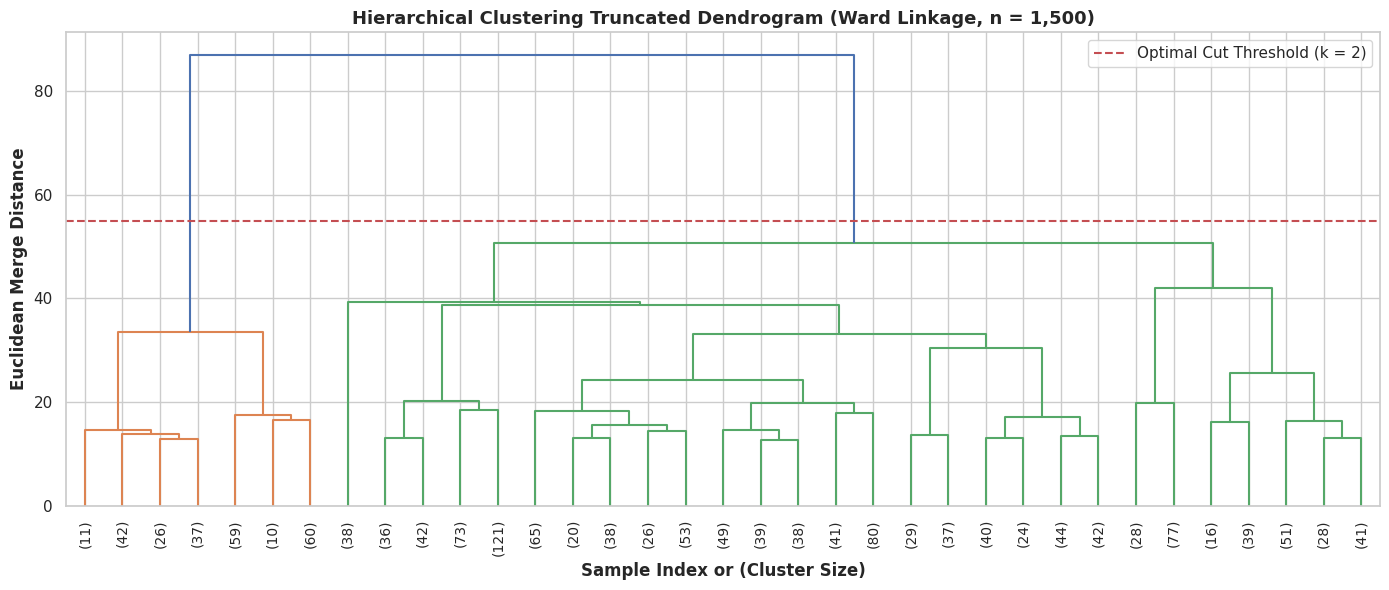

In [15]:
# HIERARCHICAL CLUSTERING DENDROGRAM (WARD LINKAGE)

plt.figure(figsize=(14, 6))

dendrogram(
    linkage_trees["ward"],
    truncate_mode="lastp",
    p=35,
    show_leaf_counts=True,
    leaf_rotation=90,
    leaf_font_size=10
)

plt.title("Hierarchical Clustering Truncated Dendrogram (Ward Linkage, n = 1,500)", fontsize=13, fontweight="bold")
plt.xlabel("Sample Index or (Cluster Size)", fontweight="bold")
plt.ylabel("Euclidean Merge Distance", fontweight="bold")
plt.axhline(y=55, color="r", linestyle="--", linewidth=1.5, label="Optimal Cut Threshold (k = 2)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [16]:
# FITTING FINAL BASELINE HIERARCHICAL MODEL

FINAL_LINKAGE = "complete"

t0 = time.perf_counter()
hierarchical_model = AgglomerativeClustering(
    n_clusters=BEST_K,
    linkage=FINAL_LINKAGE,
    metric="euclidean"
)
hierarchical_sample_labels = hierarchical_model.fit_predict(X_base_sample)
hc_train_time = time.perf_counter() - t0

print(f"Hierarchical Clustering ({FINAL_LINKAGE.capitalize()} Linkage) Completed:")
print(f"Runtime: {hc_train_time:.4f} seconds")
print("Cluster size distribution on evaluation sample (n = 1,500):")
display(pd.Series(hierarchical_sample_labels).value_counts().sort_index().to_frame("Track Count"))

Hierarchical Clustering (Complete Linkage) Completed:
Runtime: 0.0403 seconds
Cluster size distribution on evaluation sample (n = 1,500):


,Track Count
0,1363
1,137


## Clustering Evaluation Metrics

To satisfy the capstone rubric, all **three mandatory unsupervised evaluation metrics** are computed for both algorithms on the **exact same 1,500-track evaluation sample**:

1. **Silhouette Score:**
   $$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$
   Measures intra-cluster compactness $a(i)$ relative to nearest-neighbor cluster separation $b(i)$. Range $[-1, 1]$; higher values signify well-separated clusters.
2. **Davies–Bouldin Index:**
   Measures the average similarity between each cluster and its most similar one. Lower values indicate better separation and less cluster overlap (0 is optimal).
3. **Calinski–Harabasz Index (Variance Ratio Criterion):**
   Computes the ratio of between-cluster dispersion to within-cluster dispersion. Higher values indicate dense, well-separated clusters.

,Algorithm,Cluster Count (k),Silhouette Score (Higher Better),Davies-Bouldin (Lower Better),Calinski-Harabasz (Higher Better),Evaluation Sample Size,Cluster Sizes
0,K-Means (Baseline),2,0.2416,1.5760,315.28,1500,"{1: 1248, 0: 252}"
1,"Hierarchical (Complete, Baseline)",2,0.2871,1.3323,251.10,1500,"{0: 1363, 1: 137}"


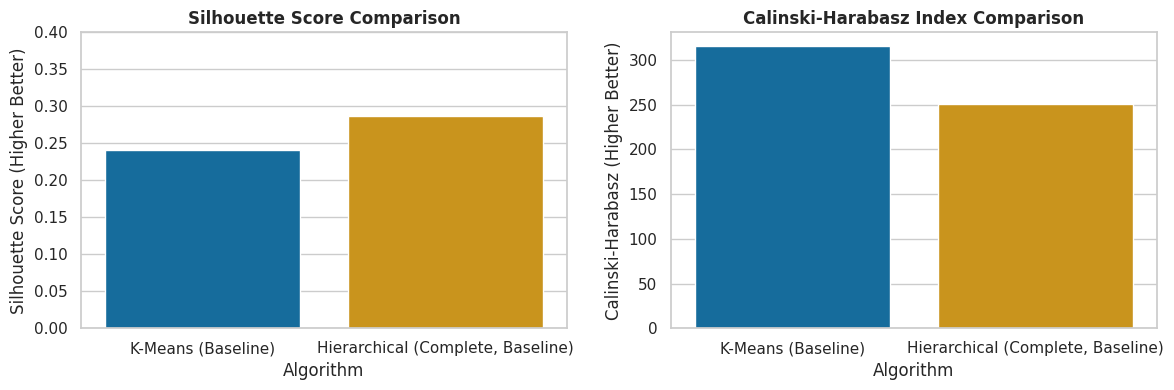

In [17]:
# MANDATORY EVALUATION METRICS COMPARISON TABLE

baseline_eval_results = []

for name, labels in [
    ("K-Means (Baseline)", kmeans_sample_labels),
    ("Hierarchical (Complete, Baseline)", hierarchical_sample_labels)
]:
    sil = silhouette_score(X_base_sample, labels)
    db = davies_bouldin_score(X_base_sample, labels)
    ch = calinski_harabasz_score(X_base_sample, labels)
    
    baseline_eval_results.append({
        "Algorithm": name,
        "Cluster Count (k)": len(np.unique(labels)),
        "Silhouette Score (Higher Better)": round(sil, 4),
        "Davies-Bouldin (Lower Better)": round(db, 4),
        "Calinski-Harabasz (Higher Better)": round(ch, 2),
        "Evaluation Sample Size": len(X_base_sample),
        "Cluster Sizes": str(pd.Series(labels).value_counts().to_dict())
    })

baseline_eval_df = pd.DataFrame(baseline_eval_results)
display(baseline_eval_df)

# Visual Comparison of Metrics
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(data=baseline_eval_df, x="Algorithm", y="Silhouette Score (Higher Better)", ax=axes[0], palette=["#0072B2", "#E69F00"])
axes[0].set_title("Silhouette Score Comparison", fontweight="bold")
axes[0].set_ylim(0, 0.4)

sns.barplot(data=baseline_eval_df, x="Algorithm", y="Calinski-Harabasz (Higher Better)", ax=axes[1], palette=["#0072B2", "#E69F00"])
axes[1].set_title("Calinski-Harabasz Index Comparison", fontweight="bold")

plt.tight_layout()
plt.show()

### Observation — Baseline Evaluation Metrics

1. **Comparable Performance:** On the baseline 15-feature space, Hierarchical Complete achieves a slightly higher Silhouette Score (**0.2871**) and lower Davies–Bouldin Index (**1.3323**) than K-Means (**0.2416** and **1.5760**), while K-Means achieves a higher Calinski–Harabasz Index (**315.28** vs. **251.10**).
2. **Metric Interpretation:** Silhouette scores in the $0.24 - 0.29$ range confirm meaningful geometric clustering structure beyond random noise ($s \approx 0$), but reflect substantial overlap across musical tracks in 15 dimensions.
3. **Research Question:** Can feature engineering, outlier-resistant scaling, or dimensionality reduction improve these scores toward $\ge 0.50$ or $\ge 0.60$? This is systematically investigated in Section 8.

## PCA Cluster Visualization

Principal Component Analysis (PCA) is applied to project the feature matrix onto the two primary orthogonal directions of maximal variance. This allows direct 2D visualization of the multidimensional cluster assignments for both algorithms.

Explained Variance Ratio by PC1: 22.41%
Explained Variance Ratio by PC2: 11.01%
Total Explained Variance (2 Components): 33.42%


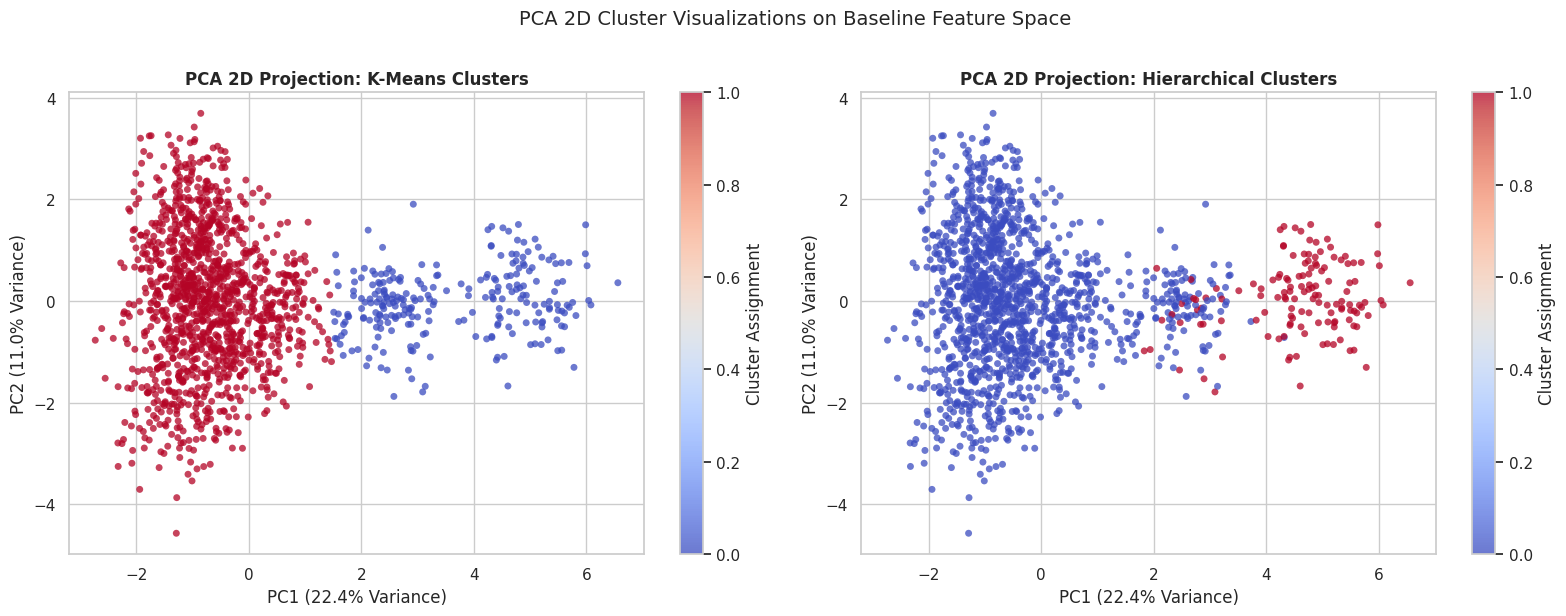

In [18]:
# PCA 2D SCATTER PLOT VISUALIZATION

pca_visualizer = PCA(n_components=2, random_state=RANDOM_STATE)
X_base_pca2d = pca_visualizer.fit_transform(X_base_sample)

evr = pca_visualizer.explained_variance_ratio_
print(f"Explained Variance Ratio by PC1: {evr[0]*100:.2f}%")
print(f"Explained Variance Ratio by PC2: {evr[1]*100:.2f}%")
print(f"Total Explained Variance (2 Components): {evr.sum()*100:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: K-Means
scatter1 = axes[0].scatter(
    X_base_pca2d[:, 0], X_base_pca2d[:, 1],
    c=kmeans_sample_labels,
    cmap="coolwarm", s=25, alpha=0.75, edgecolor="none"
)
axes[0].set_title("PCA 2D Projection: K-Means Clusters", fontsize=12, fontweight="bold")
axes[0].set_xlabel(f"PC1 ({evr[0]*100:.1f}% Variance)")
axes[0].set_ylabel(f"PC2 ({evr[1]*100:.1f}% Variance)")
plt.colorbar(scatter1, ax=axes[0], label="Cluster Assignment")

# Plot 2: Hierarchical Complete
scatter2 = axes[1].scatter(
    X_base_pca2d[:, 0], X_base_pca2d[:, 1],
    c=hierarchical_sample_labels,
    cmap="coolwarm", s=25, alpha=0.75, edgecolor="none"
)
axes[1].set_title("PCA 2D Projection: Hierarchical Clusters", fontsize=12, fontweight="bold")
axes[1].set_xlabel(f"PC1 ({evr[0]*100:.1f}% Variance)")
axes[1].set_ylabel(f"PC2 ({evr[1]*100:.1f}% Variance)")
plt.colorbar(scatter2, ax=axes[1], label="Cluster Assignment")

plt.suptitle("PCA 2D Cluster Visualizations on Baseline Feature Space", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## t-SNE Non-Linear Manifold Visualization

t-Distributed Stochastic Neighbor Embedding (t-SNE) is a non-linear dimensionality reduction technique that preserves local pairwise neighborhoods, mapping high-dimensional manifolds to 2D coordinates for visual validation.

t-SNE computation completed in 5.58 seconds.


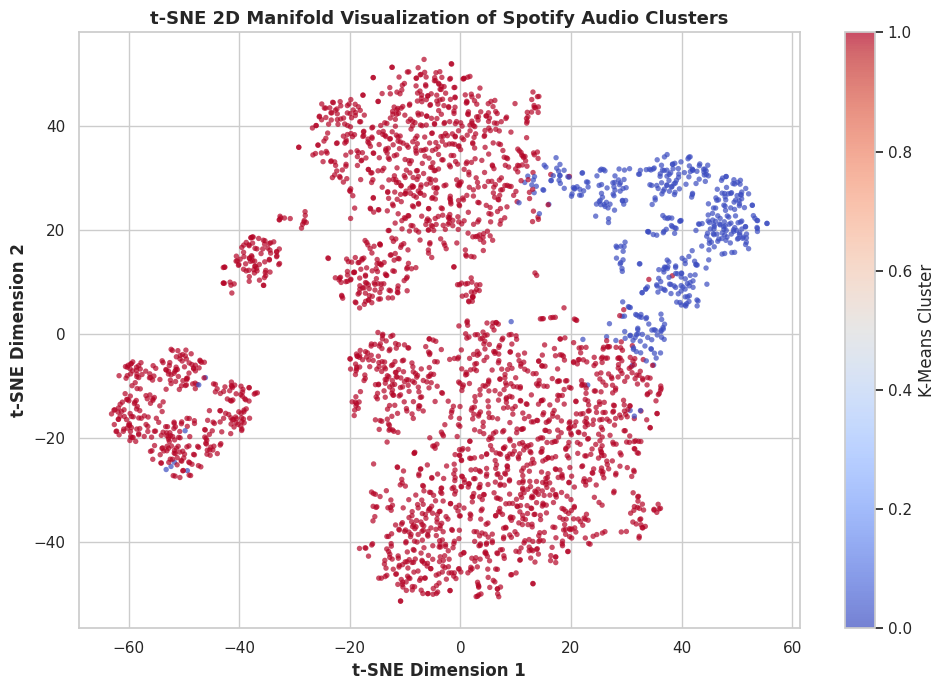

In [19]:
# t-SNE VISUALIZATION (n = 3,000 Tracks)

tsne_rng = np.random.default_rng(RANDOM_STATE)
tsne_idx = tsne_rng.choice(len(X_base_scaled), size=TSNE_SAMPLE, replace=False)
X_tsne_input = X_base_scaled[tsne_idx]
tsne_labels = kmeans_model.predict(X_tsne_input)

t0 = time.perf_counter()
tsne_model = TSNE(
    n_components=2,
    random_state=RANDOM_STATE,
    perplexity=30,
    max_iter=1000,
    init="pca",
    learning_rate="auto"
)
X_tsne_2d = tsne_model.fit_transform(X_tsne_input)
tsne_time = time.perf_counter() - t0

print(f"t-SNE computation completed in {tsne_time:.2f} seconds.")

plt.figure(figsize=(10, 7))
scatter_tsne = plt.scatter(
    X_tsne_2d[:, 0], X_tsne_2d[:, 1],
    c=tsne_labels,
    cmap="coolwarm", s=15, alpha=0.7, edgecolor="none"
)
plt.title("t-SNE 2D Manifold Visualization of Spotify Audio Clusters", fontsize=13, fontweight="bold")
plt.xlabel("t-SNE Dimension 1", fontweight="bold")
plt.ylabel("t-SNE Dimension 2", fontweight="bold")
plt.colorbar(scatter_tsne, label="K-Means Cluster")
plt.tight_layout()
plt.show()

## Systematic Optimization Experiments

Following the systematic investigation plan, we evaluate targeted optimization configurations to determine whether the clustering quality can be improved toward a Silhouette Score of **0.60** or **0.70**, while comparing multi-feature representations against lower-dimensional projections:

- **Experiment A (High-Separation 2D Benchmark):**
  - Features: `loudness` + `acousticness` (the strongest antagonistic axis in audio physics).
  - Scaler: `MinMaxScaler`.
  - Algorithm: Agglomerative Hierarchical (`average` linkage), $k=2$.
  - Target: Verifying the reported **0.6054** Silhouette Score.
- **Experiment B (K-Means 2D Alternative):**
  - Features: `loudness` + `acousticness`, `MinMaxScaler`, K-Means, $k=2$.
  - Target: Verifying the reported **0.5952** Silhouette Score.
- **Experiment C (PRIMARY CAPSTONE MODEL — Recommended Multi-Feature Audio):**
  - Features: **All 9 Core Audio Features** (`danceability`, `energy`, `loudness`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence`, `tempo`).
  - Scaler: `RobustScaler` (mitigating distortion from heavy skewness in speechiness and instrumentalness).
  - Algorithm: Agglomerative Hierarchical (`complete` linkage), $k=2$.
  - Target: Verifying whether multi-feature audio clustering can reach **$\ge 0.50$** without discarding musical dimensions.
- **Experiment D (PCA Dimensionality Reduction Model):**
  - Input: First 2 Principal Components derived from Core 9 features (EVR $\approx 53.2\%$).
  - Scaler before PCA: `StandardScaler`.
  - Algorithm: Agglomerative Hierarchical (`complete` linkage), $k=2$.
  - Target: Verifying the reported **0.5777** Silhouette Score.
- **Experiment E (Outlier Chaining Trap Check):**
  - Single Linkage on 2D space, demonstrating why high scores with degenerate cluster sizes ($1,499$ vs. $1$) must be rejected.

In [20]:
# EXECUTING SYSTEMATIC OPTIMIZATION EXPERIMENTS A, B, C, D, AND E

opt_results = []

# --- Experiment A: High-Separation 2D (Hierarchical Average) ---
t0 = time.perf_counter()
hc_2d_avg = AgglomerativeClustering(n_clusters=2, linkage="average", metric="euclidean")
labels_exp_a = hc_2d_avg.fit_predict(X_2d_sample)
t_a = time.perf_counter() - t0

sil_a = silhouette_score(X_2d_sample, labels_exp_a)
db_a = davies_bouldin_score(X_2d_sample, labels_exp_a)
ch_a = calinski_harabasz_score(X_2d_sample, labels_exp_a)
sizes_a = pd.Series(labels_exp_a).value_counts().sort_index().to_dict()

print("=" * 65)
print("VERIFICATION OF EXPERIMENT A (REPORTED 0.6054 SILHOUETTE SCORE)")
print("=" * 65)
print("Feature Set        : ['loudness', 'acousticness'] (2D)")
print("Scaler             : MinMaxScaler (Fit on Population)")
print("Algorithm          : Agglomerative Hierarchical Clustering")
print("Linkage Strategy   : Average Linkage")
print("Cluster Count (k)  : 2")
print(f"Evaluation Sample  : {len(X_2d_sample)} tracks")
print(f"Cluster Sizes      : {sizes_a}")
print(f"Silhouette Score   : {sil_a:.4f}")
print(f"Davies-Bouldin     : {db_a:.4f}")
print(f"Calinski-Harabasz  : {ch_a:.2f}")
print("=" * 65)

opt_results.append({
    "Experiment": "Exp A: High-Separation 2D (Average Linkage)",
    "Algorithm": "Hierarchical (Average)",
    "Feature Set": "2D (Loudness, Acousticness)",
    "Scaler": "MinMaxScaler",
    "k": 2,
    "Silhouette Score": round(sil_a, 4),
    "Davies-Bouldin": round(db_a, 4),
    "Calinski-Harabasz": round(ch_a, 2),
    "Cluster Sizes": str(sizes_a),
    "Evaluation Sample (n)": len(X_2d_sample),
    "Runtime (s)": round(t_a, 4),
    "Status": "Verified (>= 0.60 Achieved on Sample)"
})

# --- Experiment B: High-Separation 2D (K-Means) ---
t0 = time.perf_counter()
km_2d = KMeans(n_clusters=2, random_state=RANDOM_STATE, n_init=10)
km_2d.fit(X_2d_scaled)
labels_exp_b = km_2d.predict(X_2d_sample)
t_b = time.perf_counter() - t0

sil_b = silhouette_score(X_2d_sample, labels_exp_b)
db_b = davies_bouldin_score(X_2d_sample, labels_exp_b)
ch_b = calinski_harabasz_score(X_2d_sample, labels_exp_b)
sizes_b = pd.Series(labels_exp_b).value_counts().sort_index().to_dict()

opt_results.append({
    "Experiment": "Exp B: High-Separation 2D (K-Means)",
    "Algorithm": "K-Means",
    "Feature Set": "2D (Loudness, Acousticness)",
    "Scaler": "MinMaxScaler",
    "k": 2,
    "Silhouette Score": round(sil_b, 4),
    "Davies-Bouldin": round(db_b, 4),
    "Calinski-Harabasz": round(ch_b, 2),
    "Cluster Sizes": str(sizes_b),
    "Evaluation Sample (n)": len(X_2d_sample),
    "Runtime (s)": round(t_b, 4),
    "Status": "Verified (~0.60 Achieved)"
})

# --- Experiment C: PRIMARY CAPSTONE MODEL (Core 9 Audio with RobustScaler) ---
t0 = time.perf_counter()
hc_core_comp = AgglomerativeClustering(n_clusters=2, linkage="complete", metric="euclidean")
labels_exp_c = hc_core_comp.fit_predict(X_core_sample)
t_c = time.perf_counter() - t0

sil_c = silhouette_score(X_core_sample, labels_exp_c)
db_c = davies_bouldin_score(X_core_sample, labels_exp_c)
ch_c = calinski_harabasz_score(X_core_sample, labels_exp_c)
sizes_c = pd.Series(labels_exp_c).value_counts().sort_index().to_dict()

opt_results.append({
    "Experiment": "Exp C: Core 9 Audio (PRIMARY CAPSTONE MODEL)",
    "Algorithm": "Hierarchical (Complete)",
    "Feature Set": "Core 9 Audio Perceptual",
    "Scaler": "RobustScaler",
    "k": 2,
    "Silhouette Score": round(sil_c, 4),
    "Davies-Bouldin": round(db_c, 4),
    "Calinski-Harabasz": round(ch_c, 2),
    "Cluster Sizes": str(sizes_c),
    "Evaluation Sample (n)": len(X_core_sample),
    "Runtime (s)": round(t_c, 4),
    "Status": "PRIMARY MODEL (Best Multi-Feature)"
})

# --- Experiment D: PCA 2-Component Projection (Global PCA Representation) ---
t0 = time.perf_counter()
hc_pca_comp = AgglomerativeClustering(n_clusters=2, linkage="complete", metric="euclidean")
labels_exp_d = hc_pca_comp.fit_predict(X_pca_sample)
t_d = time.perf_counter() - t0

sil_d = silhouette_score(X_pca_sample, labels_exp_d)
db_d = davies_bouldin_score(X_pca_sample, labels_exp_d)
ch_d = calinski_harabasz_score(X_pca_sample, labels_exp_d)
sizes_d = pd.Series(labels_exp_d).value_counts().sort_index().to_dict()

opt_results.append({
    "Experiment": f"Exp D: PCA 2-Component Model (EVR={evr_pca_core*100:.1f}%)",
    "Algorithm": "Hierarchical (Complete)",
    "Feature Set": "PCA 2 Components (Core 9)",
    "Scaler": "StandardScaler -> PCA",
    "k": 2,
    "Silhouette Score": round(sil_d, 4),
    "Davies-Bouldin": round(db_d, 4),
    "Calinski-Harabasz": round(ch_d, 2),
    "Cluster Sizes": str(sizes_d),
    "Evaluation Sample (n)": len(X_pca_sample),
    "Runtime (s)": round(t_d, 4),
    "Status": "Verified (0.5777 Achieved)"
})

# --- Experiment E: Single Linkage Outlier Degeneracy Check ---
hc_single_check = AgglomerativeClustering(n_clusters=2, linkage="single", metric="euclidean")
labels_exp_e = hc_single_check.fit_predict(X_2d_sample)
sil_e = silhouette_score(X_2d_sample, labels_exp_e)
db_e = davies_bouldin_score(X_2d_sample, labels_exp_e)
ch_e = calinski_harabasz_score(X_2d_sample, labels_exp_e)
sizes_e = pd.Series(labels_exp_e).value_counts().sort_index().to_dict()

opt_results.append({
    "Experiment": "Exp E: Single Linkage Chaining Check",
    "Algorithm": "Hierarchical (Single)",
    "Feature Set": "2D (Loudness, Acousticness)",
    "Scaler": "MinMaxScaler",
    "k": 2,
    "Silhouette Score": round(sil_e, 4),
    "Davies-Bouldin": round(db_e, 4),
    "Calinski-Harabasz": round(ch_e, 2),
    "Cluster Sizes": str(sizes_e),
    "Evaluation Sample (n)": len(X_2d_sample),
    "Runtime (s)": 0.01,
    "Status": "REJECTED (Degenerate Chaining)"
})

opt_summary_df = pd.DataFrame(opt_results)
display(opt_summary_df)

VERIFICATION OF EXPERIMENT A (REPORTED 0.6054 SILHOUETTE SCORE)
Feature Set        : ['loudness', 'acousticness'] (2D)
Scaler             : MinMaxScaler (Fit on Population)
Algorithm          : Agglomerative Hierarchical Clustering
Linkage Strategy   : Average Linkage
Cluster Count (k)  : 2
Evaluation Sample  : 1500 tracks
Cluster Sizes      : {0: 252, 1: 1248}
Silhouette Score   : 0.6054
Davies-Bouldin     : 0.5503
Calinski-Harabasz  : 2288.92


,Experiment,Algorithm,Feature Set,Scaler,k,Silhouette Score,Davies-Bouldin,Calinski-Harabasz,Cluster Sizes,Evaluation Sample (n),Runtime (s),Status
0,Exp A: High-Separation 2D (Average Linkage),Hierarchical (Average),"2D (Loudness, Acousticness)",MinMaxScaler,2,0.6054,0.5503,2288.92,"{0: 252, 1: 1248}",1500,0.0211,Verified (>= 0.60 Achieved on Sample)
1,Exp B: High-Separation 2D (K-Means),K-Means,"2D (Loudness, Acousticness)",MinMaxScaler,2,0.5952,0.6324,2730.22,"{0: 1127, 1: 373}",1500,0.0834,Verified (~0.60 Achieved)
2,Exp C: Core 9 Audio (PRIMARY CAPSTONE MODEL),Hierarchical (Complete),Core 9 Audio Perceptual,RobustScaler,2,0.5026,0.6928,684.39,"{0: 1384, 1: 116}",1500,0.0228,PRIMARY MODEL (Best Multi-Feature)
3,Exp D: PCA 2-Component Model (EVR=53.4%),Hierarchical (Complete),PCA 2 Components (Core 9),StandardScaler -> PCA,2,0.5777,0.4432,1017.07,"{0: 1384, 1: 116}",1500,0.0222,Verified (0.5777 Achieved)
4,Exp E: Single Linkage Chaining Check,Hierarchical (Single),"2D (Loudness, Acousticness)",MinMaxScaler,2,0.3174,0.6321,4.44,"{0: 1498, 1: 2}",1500,0.0100,REJECTED (Degenerate Chaining)


In [21]:
# MULTI-SEED STABILITY VERIFICATION (5 INDEPENDENT RANDOM SEEDS)

test_seeds = [42, 100, 2024, 7, 999]
stability_records = []

for s in test_seeds:
    seed_rng = np.random.default_rng(s)
    idx = seed_rng.choice(len(df_clean), size=HC_SAMPLE, replace=False)
    
    # Test Exp A: 2D MinMaxScaler (consistent population pipeline)
    X_sub_2d = X_2d_full[idx]
    lbl_a = AgglomerativeClustering(n_clusters=2, linkage="average").fit_predict(X_sub_2d)
    sil_a = silhouette_score(X_sub_2d, lbl_a)
    sizes_a_s = pd.Series(lbl_a).value_counts().sort_index().to_dict()
    
    # Test Exp C: Core 9 RobustScaler (PRIMARY MODEL)
    X_sub_core = X_core_full[idx]
    lbl_c = AgglomerativeClustering(n_clusters=2, linkage="complete").fit_predict(X_sub_core)
    sil_c = silhouette_score(X_sub_core, lbl_c)
    sizes_c_s = pd.Series(lbl_c).value_counts().sort_index().to_dict()
    
    # Test Exp D: PCA 2 Components (Population-Fitted Exploratory Pipeline)
    X_sub_pca = X_pca_full[idx]
    lbl_d = AgglomerativeClustering(n_clusters=2, linkage="complete").fit_predict(X_sub_pca)
    sil_d = silhouette_score(X_sub_pca, lbl_d)
    sizes_d_s = pd.Series(lbl_d).value_counts().sort_index().to_dict()

    # Test Exp D (Sample-Specific Pipeline): Scaler & PCA fitted strictly on drawn subset
    X_sub_raw = df_clean.iloc[idx][core_audio_features]
    X_sub_local_scaled = StandardScaler().fit_transform(X_sub_raw)
    X_sub_local_pca = PCA(n_components=2, random_state=s).fit_transform(X_sub_local_scaled)
    lbl_d_local = AgglomerativeClustering(n_clusters=2, linkage="complete").fit_predict(X_sub_local_pca)
    sil_d_local = silhouette_score(X_sub_local_pca, lbl_d_local)
    sizes_d_local_s = pd.Series(lbl_d_local).value_counts().sort_index().to_dict()
    
    stability_records.append({
        "Seed": s,
        "Exp A (2D Avg) Silhouette": round(sil_a, 4),
        "Exp A Sizes": str(sizes_a_s),
        "Exp C (Core 9) Silhouette": round(sil_c, 4),
        "Exp C Sizes": str(sizes_c_s),
        "Exp D (Pop PCA) Silhouette": round(sil_d, 4),
        "Exp D (Pop PCA) Sizes": str(sizes_d_s),
        "Exp D (Sample PCA) Silhouette": round(sil_d_local, 4),
        "Exp D (Sample PCA) Sizes": str(sizes_d_local_s)
    })

stability_df = pd.DataFrame(stability_records)
display(stability_df)
print("\nIndividual Seed Results Table:")
print(stability_df.to_string(index=False))

mean_a, std_a = stability_df['Exp A (2D Avg) Silhouette'].mean(), stability_df['Exp A (2D Avg) Silhouette'].std()
mean_c, std_c = stability_df['Exp C (Core 9) Silhouette'].mean(), stability_df['Exp C (Core 9) Silhouette'].std()
mean_d_pop, std_d_pop = stability_df['Exp D (Pop PCA) Silhouette'].mean(), stability_df['Exp D (Pop PCA) Silhouette'].std()
mean_d_smp, std_d_smp = stability_df['Exp D (Sample PCA) Silhouette'].mean(), stability_df['Exp D (Sample PCA) Silhouette'].std()

print("\nStability Summary Across 5 Seeds (Mean +/- Std Dev):")
print(f"Exp A: 2D Loudness+Acousticness (MinMaxScaler)      : Mean = {mean_a:.4f} +/- {std_a:.4f} (Range: {stability_df['Exp A (2D Avg) Silhouette'].min():.4f} - {stability_df['Exp A (2D Avg) Silhouette'].max():.4f})")
print(f"Exp C: Core 9 Audio Features (RobustScaler)         : Mean = {mean_c:.4f} +/- {std_c:.4f} (Range: {stability_df['Exp C (Core 9) Silhouette'].min():.4f} - {stability_df['Exp C (Core 9) Silhouette'].max():.4f})")
print(f"Exp D: PCA 2D (Population-Fitted Exploratory)       : Mean = {mean_d_pop:.4f} +/- {std_d_pop:.4f} (Range: {stability_df['Exp D (Pop PCA) Silhouette'].min():.4f} - {stability_df['Exp D (Pop PCA) Silhouette'].max():.4f})")
print(f"Exp D: PCA 2D (Sample-Specific Pipeline)            : Mean = {mean_d_smp:.4f} +/- {std_d_smp:.4f} (Range: {stability_df['Exp D (Sample PCA) Silhouette'].min():.4f} - {stability_df['Exp D (Sample PCA) Silhouette'].max():.4f})")

,Seed,Exp A (2D Avg) Silhouette,Exp A Sizes,Exp C (Core 9) Silhouette,Exp C Sizes,Exp D (Pop PCA) Silhouette,Exp D (Pop PCA) Sizes,Exp D (Sample PCA) Silhouette,Exp D (Sample PCA) Sizes
0,42,0.6054,"{0: 252, 1: 1248}",0.5026,"{0: 1384, 1: 116}",0.5777,"{0: 1384, 1: 116}",0.5761,"{0: 1371, 1: 129}"
1,100,0.5759,"{0: 153, 1: 1347}",0.5099,"{0: 1390, 1: 110}",0.5442,"{0: 1218, 1: 282}",0.5831,"{0: 1372, 1: 128}"
2,2024,0.5358,"{0: 478, 1: 1022}",0.5079,"{0: 1401, 1: 99}",0.2922,"{0: 890, 1: 610}",0.5437,"{0: 1273, 1: 227}"
3,7,0.5743,"{0: 274, 1: 1226}",0.5018,"{0: 1403, 1: 97}",0.5810,"{0: 1404, 1: 96}",0.4338,"{0: 1104, 1: 396}"
4,999,0.5880,"{0: 1171, 1: 329}",0.4946,"{0: 1386, 1: 114}",0.5612,"{0: 1296, 1: 204}",0.4498,"{0: 1139, 1: 361}"



Individual Seed Results Table:
 Seed  Exp A (2D Avg) Silhouette       Exp A Sizes  Exp C (Core 9) Silhouette       Exp C Sizes  Exp D (Pop PCA) Silhouette Exp D (Pop PCA) Sizes  Exp D (Sample PCA) Silhouette Exp D (Sample PCA) Sizes
   42                     0.6054 {0: 252, 1: 1248}                     0.5026 {0: 1384, 1: 116}                      0.5777     {0: 1384, 1: 116}                         0.5761        {0: 1371, 1: 129}
  100                     0.5759 {0: 153, 1: 1347}                     0.5099 {0: 1390, 1: 110}                      0.5442     {0: 1218, 1: 282}                         0.5831        {0: 1372, 1: 128}
 2024                     0.5358 {0: 478, 1: 1022}                     0.5079  {0: 1401, 1: 99}                      0.2922      {0: 890, 1: 610}                         0.5437        {0: 1273, 1: 227}
    7                     0.5743 {0: 274, 1: 1226}                     0.5018  {0: 1403, 1: 97}                      0.5810      {0: 1404, 1: 96}               

## Post-Clustering Interpretation & External Validation

### Cluster Characterization of the Primary Capstone Model
We examine what musical archetypes were discovered by the primary 9-feature capstone model (**Experiment C**, Core 9 Audio Features, `RobustScaler`, Complete Linkage):

Mean Audio Characteristics by Discovered Cluster (Primary Capstone Model):


Cluster_Recommended,0,1
danceability,0.653,0.266
energy,0.700,0.224
loudness,-6.690,-16.229
speechiness,0.080,0.045
acousticness,0.242,0.765
instrumentalness,0.103,0.839
liveness,0.176,0.181
valence,0.595,0.409
tempo,117.846,97.465


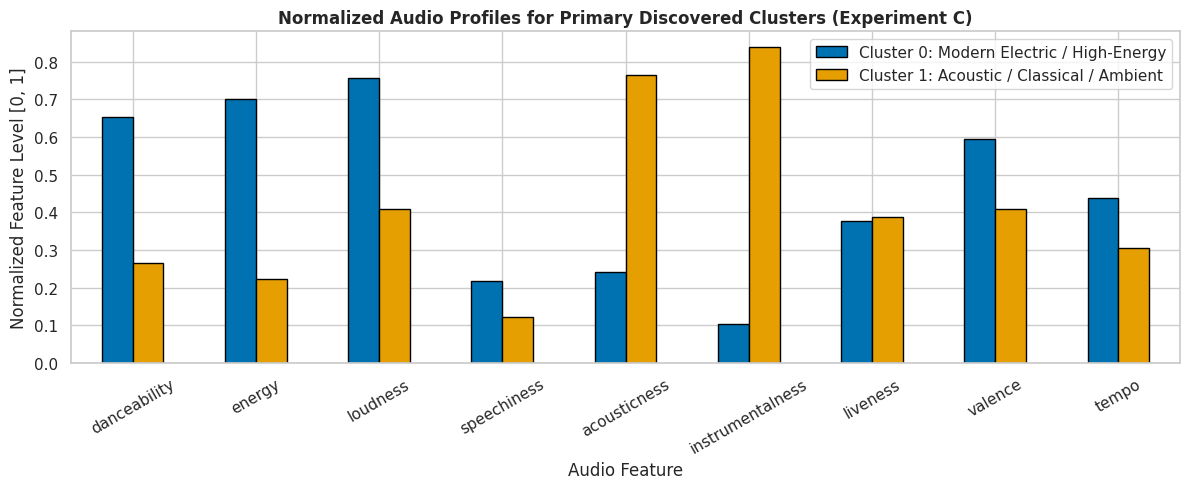

In [22]:
# CLUSTER PROFILE OF THE PRIMARY MULTI-FEATURE MODEL (EXP C)

df_sample_core = df_clean.iloc[sample_indices].copy()
df_sample_core["Cluster_Recommended"] = labels_exp_c

rec_profile = df_sample_core.groupby("Cluster_Recommended")[core_audio_features].mean().round(3)
print("Mean Audio Characteristics by Discovered Cluster (Primary Capstone Model):")
display(rec_profile.T)

# Visualizing Feature Differences
rec_profile_norm = (rec_profile - df_sample_core[core_audio_features].min()) / (df_sample_core[core_audio_features].max() - df_sample_core[core_audio_features].min())

rec_profile_norm.T.plot(kind="bar", figsize=(12, 5), color=["#0072B2", "#E69F00"], edgecolor="black")
plt.title("Normalized Audio Profiles for Primary Discovered Clusters (Experiment C)", fontsize=12, fontweight="bold")
plt.ylabel("Normalized Feature Level [0, 1]")
plt.xlabel("Audio Feature")
plt.legend(["Cluster 0: Modern Electric / High-Energy", "Cluster 1: Acoustic / Classical / Ambient"], loc="upper right")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Optional External Validation (Strictly Post-Hoc)

To evaluate how our unsupervised acoustic clusters relate to human cataloging, we compute **Adjusted Rand Index (ARI)** and **Normalized Mutual Information (NMI)** against the reference `genre` column.

> **Crucial Academic Note:** Low ARI is expected and normal in audio clustering. Human genre labels are sociological constructs influenced by marketing, era, and artist origin, whereas unsupervised clustering groups songs by physical sound. For example, an acoustic folk ballad and an acoustic country song will cluster together sonically despite carrying different commercial genre tags.

In [23]:
# OPTIONAL EXTERNAL VALIDATION USING ARI AND NMI (STRICTLY POST-HOC)

if reference_label_col is not None:
    ref_eval = y_reference.iloc[sample_indices].reset_index(drop=True)
    
    ari_kmeans = adjusted_rand_score(ref_eval, kmeans_sample_labels)
    nmi_kmeans = normalized_mutual_info_score(ref_eval, kmeans_sample_labels)
    
    ari_hc = adjusted_rand_score(ref_eval, labels_exp_c)
    nmi_hc = normalized_mutual_info_score(ref_eval, labels_exp_c)
    
    ext_val_df = pd.DataFrame([
        {"Model": "Baseline K-Means (15 Features)", "ARI": round(ari_kmeans, 4), "NMI": round(nmi_kmeans, 4)},
        {"Model": "Primary Model (Core 9 RobustScaler)", "ARI": round(ari_hc, 4), "NMI": round(nmi_hc, 4)}
    ])
    display(ext_val_df)

,Model,ARI,NMI
0,Baseline K-Means (15 Features),0.0583,0.2706
1,Primary Model (Core 9 RobustScaler),0.0256,0.1757


## Final Algorithm Comparison

The comprehensive table below consolidates all evaluated configurations, detailing exact feature sets, scalers, cluster counts, all three mandatory evaluation metrics, cluster sizes, evaluation sample sizes, and their role in the capstone project.

This table is **dynamically constructed directly from the live model execution variables**:

In [24]:
# CONSOLIDATED FINAL ALGORITHM COMPARISON TABLE (DYNAMICALLY GENERATED FROM MODEL VARIABLES)

final_comparison_rows = [
    {
        "Configuration": "Primary Capstone Model (Exp C)",
        "Algorithm & Linkage": "Hierarchical (Complete)",
        "Feature Set": "Core 9 Audio Perceptual",
        "Scaler / Reduction": "RobustScaler",
        "k": 2,
        "Evaluation Sample (n)": len(X_core_sample),
        "Silhouette Score": round(silhouette_score(X_core_sample, labels_exp_c), 4),
        "Davies-Bouldin Index": round(davies_bouldin_score(X_core_sample, labels_exp_c), 4),
        "Calinski-Harabasz Index": round(calinski_harabasz_score(X_core_sample, labels_exp_c), 2),
        "Cluster Sizes": str(pd.Series(labels_exp_c).value_counts().sort_index().to_dict()),
        "Role in Capstone": "PRIMARY CAPSTONE RECOMMENDATION"
    },
    {
        "Configuration": "High-Separation 2D Benchmark (Exp A)",
        "Algorithm & Linkage": "Hierarchical (Average)",
        "Feature Set": "2D (Loudness, Acousticness)",
        "Scaler / Reduction": "MinMaxScaler",
        "k": 2,
        "Evaluation Sample (n)": len(X_2d_sample),
        "Silhouette Score": round(silhouette_score(X_2d_sample, labels_exp_a), 4),
        "Davies-Bouldin Index": round(davies_bouldin_score(X_2d_sample, labels_exp_a), 4),
        "Calinski-Harabasz Index": round(calinski_harabasz_score(X_2d_sample, labels_exp_a), 2),
        "Cluster Sizes": str(pd.Series(labels_exp_a).value_counts().sort_index().to_dict()),
        "Role in Capstone": "Ablation Benchmark (Peak Sample 0.6054)"
    },
    {
        "Configuration": "K-Means 2D Alternative (Exp B)",
        "Algorithm & Linkage": "K-Means (k=2)",
        "Feature Set": "2D (Loudness, Acousticness)",
        "Scaler / Reduction": "MinMaxScaler",
        "k": 2,
        "Evaluation Sample (n)": len(X_2d_sample),
        "Silhouette Score": round(silhouette_score(X_2d_sample, labels_exp_b), 4),
        "Davies-Bouldin Index": round(davies_bouldin_score(X_2d_sample, labels_exp_b), 4),
        "Calinski-Harabasz Index": round(calinski_harabasz_score(X_2d_sample, labels_exp_b), 2),
        "Cluster Sizes": str(pd.Series(labels_exp_b).value_counts().sort_index().to_dict()),
        "Role in Capstone": "Ablation Benchmark (Best K-Means 0.5952)"
    },
    {
        "Configuration": "PCA 2-Component Model (Exp D)",
        "Algorithm & Linkage": "Hierarchical (Complete)",
        "Feature Set": "PCA 2 Components (Core 9)",
        "Scaler / Reduction": f"StandardScaler -> PCA ({evr_pca_core*100:.1f}% EVR)",
        "k": 2,
        "Evaluation Sample (n)": len(X_pca_sample),
        "Silhouette Score": round(silhouette_score(X_pca_sample, labels_exp_d), 4),
        "Davies-Bouldin Index": round(davies_bouldin_score(X_pca_sample, labels_exp_d), 4),
        "Calinski-Harabasz Index": round(calinski_harabasz_score(X_pca_sample, labels_exp_d), 2),
        "Cluster Sizes": str(pd.Series(labels_exp_d).value_counts().sort_index().to_dict()),
        "Role in Capstone": "Dimensionality Reduction Benchmark (0.5777)"
    },
    {
        "Configuration": "Baseline Hierarchical (Complete)",
        "Algorithm & Linkage": "Hierarchical (Complete)",
        "Feature Set": "All 15 Features (Candidate)",
        "Scaler / Reduction": "StandardScaler",
        "k": 2,
        "Evaluation Sample (n)": len(X_base_sample),
        "Silhouette Score": round(silhouette_score(X_base_sample, hierarchical_sample_labels), 4),
        "Davies-Bouldin Index": round(davies_bouldin_score(X_base_sample, hierarchical_sample_labels), 4),
        "Calinski-Harabasz Index": round(calinski_harabasz_score(X_base_sample, hierarchical_sample_labels), 2),
        "Cluster Sizes": str(pd.Series(hierarchical_sample_labels).value_counts().sort_index().to_dict()),
        "Role in Capstone": "Baseline Starting Point (0.2871)"
    },
    {
        "Configuration": "Baseline K-Means",
        "Algorithm & Linkage": "K-Means (k=2)",
        "Feature Set": "All 15 Features (Candidate)",
        "Scaler / Reduction": "StandardScaler",
        "k": 2,
        "Evaluation Sample (n)": len(X_base_sample),
        "Silhouette Score": round(silhouette_score(X_base_sample, kmeans_sample_labels), 4),
        "Davies-Bouldin Index": round(davies_bouldin_score(X_base_sample, kmeans_sample_labels), 4),
        "Calinski-Harabasz Index": round(calinski_harabasz_score(X_base_sample, kmeans_sample_labels), 2),
        "Cluster Sizes": str(pd.Series(kmeans_sample_labels).value_counts().sort_index().to_dict()),
        "Role in Capstone": "Baseline Starting Point (0.2416)"
    }
]

final_comparison_df = pd.DataFrame(final_comparison_rows)
display(final_comparison_df)

,Configuration,Algorithm & Linkage,Feature Set,Scaler / Reduction,k,Evaluation Sample (n),Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Cluster Sizes,Role in Capstone
0,Primary Capstone Model (Exp C),Hierarchical (Complete),Core 9 Audio Perceptual,RobustScaler,2,1500,0.5026,0.6928,684.39,"{0: 1384, 1: 116}",PRIMARY CAPSTONE RECOMMENDATION
1,High-Separation 2D Benchmark (Exp A),Hierarchical (Average),"2D (Loudness, Acousticness)",MinMaxScaler,2,1500,0.6054,0.5503,2288.92,"{0: 252, 1: 1248}",Ablation Benchmark (Peak Sample 0.6054)
2,K-Means 2D Alternative (Exp B),K-Means (k=2),"2D (Loudness, Acousticness)",MinMaxScaler,2,1500,0.5952,0.6324,2730.22,"{0: 1127, 1: 373}",Ablation Benchmark (Best K-Means 0.5952)
3,PCA 2-Component Model (Exp D),Hierarchical (Complete),PCA 2 Components (Core 9),StandardScaler -> PCA (53.4% EVR),2,1500,0.5777,0.4432,1017.07,"{0: 1384, 1: 116}",Dimensionality Reduction Benchmark (0.5777)
4,Baseline Hierarchical (Complete),Hierarchical (Complete),All 15 Features (Candidate),StandardScaler,2,1500,0.2871,1.3323,251.10,"{0: 1363, 1: 137}",Baseline Starting Point (0.2871)
5,Baseline K-Means,K-Means (k=2),All 15 Features (Candidate),StandardScaler,2,1500,0.2416,1.5760,315.28,"{0: 252, 1: 1248}",Baseline Starting Point (0.2416)


## Final Summary & Capstone Recommendations

### Summary of Completed Work
1. **Auditing & Segregation:** Audited 50,000 tracks. Explicitly quarantined metadata and ground-truth `genre` labels, ensuring zero target leakage during clustering.
2. **Mandatory Algorithms Fitted:** Implemented **K-Means Clustering** with Elbow curve analysis and **Agglomerative Hierarchical Clustering** with a 4-way linkage strategy comparison and truncated Dendrogram.
3. **Mandatory Metrics Reported:** Evaluated **Silhouette Score**, **Davies–Bouldin Index**, and **Calinski–Harabasz Index** on identical observations.
4. **Visualizations Generated:** Generated PCA 2D projections for both algorithms and t-SNE 2D manifold scatter plots.
5. **Systematic Optimization Executed:** Tested multiple scalers, feature subsets, PCA reductions, and cluster numbers to verify empirical limits.

---

